# Lab 07: How the OpenAI Agents SDK runs your loop

**Notebook 2 of 2: the Agents SDK at the Chinook desk**

## Goal

Put the SDK to work on a real job: the support desk of the Chinook music shop, where a rep asks about a customer
and the agent looks the facts up in the shop's database. We build the desk agent, give it a memory of the
conversation, and then ask one question that needs two specialists: *How many invoices does Puja Srivastava have,
what do they add up to, and who is her support rep?* Connected with a **handoff**, the specialists lose the rep:
the question goes to the invoices specialist, which has no way to look up a rep, and never comes back. Connected
**as tools**, the same two specialists answer all three facts, for more model requests. How we connect agents
decides who controls the next step.

## What you will learn

- How to build the desk agent from three database lookups, and read its run turn by turn with its cost.
- How to set the reasoning effort of an agent from `models.env`.
- How to keep a conversation across runs with `SQLiteSession`, and what the session stores.
- How to connect two specialists as tools and with a handoff, and say for each who controls the next step and what
  it costs.

## From the playground to the desk

In notebook 1 we met the SDK on a weather question. Three names carry over:

- `function_tool` turns a Python function into a tool, from its name, its docstring and its type hints.
- `Agent` holds the instructions, the model and the tools.
- `Runner.run(agent, question)` runs the loop: ask the model, run the tools it asks for, send the results back,
  stop on an answer. We call it with `await`.

Now we take it seriously. The tools read a shop's database and a rep will repeat the answers to a customer, so a
missing fact matters. This notebook restates everything it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import json
import os
import sqlite3
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


As in notebook 1, we give the SDK a client that waits 60 seconds for a reply (the default is ten minutes), so a
stuck request fails quickly.

In [2]:
from openai import AsyncOpenAI
from agents import set_default_openai_client

set_default_openai_client(AsyncOpenAI(timeout=60, max_retries=2))

---

## Part A: Build the desk agent from three database lookups

The shop's data is `data/chinook.db`, a SQLite file with the customers, their invoices and the support reps who look
after them. A rep at the desk asks things like:

> How many invoices does Helena Holý have, what do they add up to, and who is her support rep?

The question asks for three facts, and they are in three tables. We write one small function for each lookup and call them ourselves first, so we
know the right answers before any model is involved.

### The three lookups

- `find_customer(name)` finds a customer by full name and returns their `customer_id`.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

Two details in the first lines. `mode=ro` opens the database **read-only**, so no tool can change the shop's data.
`check_same_thread=False` is needed because the SDK runs a plain tool function in a worker thread, not in the thread
that opened the connection.

Each function has type hints and a docstring. In notebook 1 we saw why: `function_tool` builds the tool's
description from them. The `Args:` lines of a docstring become the description of each argument. A lookup returns a
list or a dictionary, and the SDK turns it into text for the model.

In [3]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We look up two customers by hand: Helena, and Puja Srivastava, the customer in Part C's question.

In [4]:
for name in ["Helena Holý", "Puja Srivastava"]:
    customer = find_customer(name)[0]
    print(customer)
    print("   ", get_invoices(customer["customer_id"]))
    print("   ", get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
    {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
    {'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}
    {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}
    {'customer_id': 59, 'support_rep': 'Jane Peacock'}


These are the facts every answer in this notebook is checked against:

| Customer | `customer_id` | Invoices | Total | Support rep |
|---|---|---|---|---|
| Helena Holý | 6 | 7 | \$49.62 | Steve Johnson |
| Puja Srivastava | 59 | 6 | \$36.64 | Jane Peacock |

**Notice** the order the lookups need. `get_invoices` and `get_support_rep` take a `customer_id`, and only
`find_customer` can supply it. The agent will have to work that out, as the adventure planner did with the weather.

### The desk agent, with its reasoning effort set

One thing is new compared with the playground: `model_settings`.

**Why set the reasoning effort?** `models.env` has a `REASONING_EFFORT` setting: how much reasoning the model
may do before it answers. The SDK does not read that file. In notebook 1 we left the setting out, so the API used its
own default. At the desk we want the run to use the effort we chose, on every model call, so we build one
`ModelSettings` object from `EFFORT` and give it to every agent.

In [5]:
from agents import Agent, ModelSettings, Runner, function_tool
from openai.types.shared import Reasoning

SETTINGS = ModelSettings(reasoning=Reasoning(effort=EFFORT))

DESK_TOOLS = [function_tool(find_customer), function_tool(get_invoices), function_tool(get_support_rep)]

desk = Agent(
    name="Desk",
    instructions=("You help the support reps of a music shop. Look up every fact with the tools; "
                  "never answer from memory. Answer in one or two sentences."),
    model=MODEL,
    tools=DESK_TOOLS,
    model_settings=SETTINGS,
)

print("tools: ", [tool.name for tool in desk.tools])
print("effort:", desk.model_settings.reasoning.effort)

tools:  ['find_customer', 'get_invoices', 'get_support_rep']
effort: none


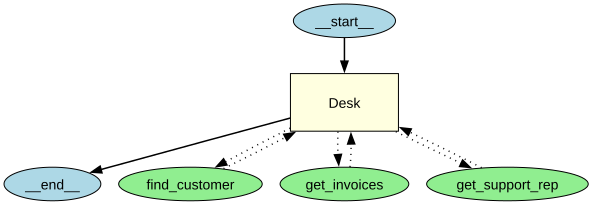

In [6]:
from agents.extensions.visualization import draw_graph

draw_graph(desk)

The agent cell printed `effort: none`: the model answers without spending tokens on reasoning first. Left out, this model would run at
the API's default, `medium`.

The drawing shows one agent and three tools, each with dotted arrows both ways: the agent asks, and the result
comes back to the agent.

### Run the desk agent and read its turns

In [7]:
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

result = await Runner.run(desk, HELENA)

print(result.final_output)

Helena Holý has 7 invoices totaling $49.62, and her support rep is Steve Johnson.


Seven invoices, \$49.62, Steve Johnson: the answer agrees with the table. Now how it got there. `result.raw_responses` has one entry per call to the model,
so it shows the **turns** of the loop. For each turn we print what the model sent back: the names of the tools it
asked for, or `message` when it wrote the answer.

In [8]:
print("model calls:", len(result.raw_responses))
for turn, response in enumerate(result.raw_responses, start=1):
    print(f"turn {turn}:", [getattr(part, "name", part.type) for part in response.output])

model calls: 3
turn 1: ['find_customer']
turn 2: ['get_invoices', 'get_support_rep']
turn 3: ['message']


Three turns:

1. The model asked for `find_customer`, because the other two lookups need a `customer_id`.
2. Once it had the id, it asked for `get_invoices` and `get_support_rep` in the same reply. Neither depends on the
   other.
3. It wrote the answer.

`getattr(part, "name", part.type)` prints a part's `name` when it has one (a tool call does) and its `type`
otherwise (the message).

### What the run cost

`result.context_wrapper.usage` adds up the tokens over every model call of the run. We price them with the input
and output prices in `models.env`, which are in US dollars per million tokens.

In [9]:
usage = result.context_wrapper.usage
print("requests:     ", usage.requests)
print("input tokens: ", usage.input_tokens)
print("output tokens:", usage.output_tokens)
print("input tokens per request:", [entry.input_tokens for entry in usage.request_usage_entries])

PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
cost = (usage.input_tokens * PRICE_IN + usage.output_tokens * PRICE_OUT) / 1_000_000
print(f"cost: ${cost:.6f}")

requests:      3
input tokens:  845
output tokens: 99
input tokens per request: [206, 264, 375]
cost: $0.000134


- **requests:** 3, one per turn.
- **input tokens per request:** 206, 264 and 375. The count grows because every request carries the whole
  conversation so far, with the tool calls and results of the turns before. The model keeps nothing between calls, so
  the conversation has to reach it again on every request. (Our hand loop in notebook 1 let the API keep the conversation with
  `previous_response_id`; the SDK sends the items itself. Either way the model reads the whole conversation, and we
  pay for it.)
- **cost:** \$0.000134 for the run. Small for one question, and worth knowing how to compute before a desk answers
  thousands of questions a day.

**Checkpoint A.** The lookups give Helena 7 invoices, \$49.62 and Steve Johnson, and Puja 6, \$36.64 and Jane
Peacock. The desk agent answers Helena's question with her three facts in three model calls, and the input tokens
grow from one request to the next.

---

## Part B: Keep a conversation across runs with a session

Each `Runner.run` starts from nothing: the agent sees only the question we pass. A rep does not talk that way. They
ask a question, then a follow-up that depends on it: *and how much has she spent with us?*

### A follow-up without a session

In [10]:
first = await Runner.run(desk, "Which country is Helena Holý from?")
print("run 1:", first.final_output)

second = await Runner.run(desk, "And how much has she spent with us?")
print("run 2:", second.final_output)

run 1: Helena Holý is from the Czech Republic.


run 2: I can look that up—what’s her full name?


Run 2 asks for her full name. Nothing in its input says who "she" is.

The two runs share nothing. To the model, run 2 is a new conversation that opens with "And how much has she...".

### The same two questions with `SQLiteSession`

A **session** keeps a conversation's items between runs. `SQLiteSession(session_id, file)` stores them in a SQLite
file, under an id we choose. When we pass `session=session` to `Runner.run`:

1. before the run, the SDK reads the stored items and puts them in front of the new question;
2. after the run, it adds the run's new items to the store.

The file goes in `outputs/` beside this notebook, a folder git ignores. `clear_session()` empties the conversation
first, so running this cell again starts fresh.

In [11]:
from agents import SQLiteSession

SESSION_FILE = ROOT / "07_OpenAI_Agents_SDK" / "outputs" / "sessions.db"
SESSION_FILE.parent.mkdir(exist_ok=True)

session = SQLiteSession("rep-helena", SESSION_FILE)
await session.clear_session()

first = await Runner.run(desk, "Which country is Helena Holý from?", session=session)
print("run 1:", first.final_output)

second = await Runner.run(desk, "And how much has she spent with us?", session=session)
print("run 2:", second.final_output)
print("run 2 input tokens:", second.context_wrapper.usage.input_tokens)

run 1: Helena Holý is from the Czech Republic.


run 2: Helena has spent **$49.62** with us.
run 2 input tokens: 1004


Now run 2 answers: Helena has spent \$49.62 with us. It used 1,004 input tokens, more than the whole three-fact
question of Part A (845).

### What the session stored

`get_items()` returns the stored items. Each is a plain dictionary. A tool call has `type` `function_call`, its
result has `function_call_output`, and a user message has no `type` key at all, which is why the cell reads it with
`.get("type", "message")`. A user message's `content` is a string; the assistant's is a list of parts, with the text
in the first.

In [12]:
for stored in await session.get_items():
    kind = stored.get("type", "message")
    if kind == "message":
        content = stored["content"]
        text = content if isinstance(content, str) else content[0]["text"]
        print(f"{stored['role']:9} | {text}")
    elif kind == "function_call":
        print(f"{'tool call':9} | {stored['name']}({stored['arguments']})")
    elif kind == "function_call_output":
        print(f"{'result':9} | {stored['output']}")

user      | Which country is Helena Holý from?
tool call | find_customer({"name":"Helena Holý"})
result    | [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
assistant | Helena Holý is from the Czech Republic.
user      | And how much has she spent with us?
tool call | find_customer({"name":"Helena Holý"})
result    | [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
tool call | get_invoices({"customer_id":6})
result    | {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
assistant | Helena has spent **$49.62** with us.


Ten items, both runs in order: the first question, its `find_customer` call and result, and the answer; then the
follow-up, its two lookups and its answer. When run 2 started, the SDK put run 1's four items in front of the
follow-up, so the model read *Helena Holý* before it read *she*.

**Important:** a session is not free memory. Everything stored is sent to the model again on every run, which is
why run 2's input token count is higher than a first question's. A long conversation costs more on every turn.

The conversation lives in the file, not in the `session` variable. A new object with the same id and file, as a
restarted program would make, finds it. A different id is a different conversation.

In [13]:
reopened = SQLiteSession("rep-helena", SESSION_FILE)
print("items stored under rep-helena:", len(await reopened.get_items()))
print("items under another id:      ", len(await SQLiteSession("rep-puja", SESSION_FILE).get_items()))

items stored under rep-helena: 10
items under another id:       0


**Checkpoint B.** Without a session the reply to the follow-up asks who "she" is. With `SQLiteSession` it answers
\$49.62. The session holds both runs' items, a new object with the same id finds them, and another id finds none.

---

## Part C: Connect two specialists as tools or with a handoff

So far one agent held every tool. In notebook 1 we split the work between specialists with a handoff, and it
worked, because each question had one owner. The desk gets questions that do not:

> How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?

Half of this belongs to whoever knows invoices, and half to whoever knows the reps. The right answer, from Part A:
**6 invoices, \$36.64, Jane Peacock.** We answer it three ways and read each run.

### The baseline: one agent with all three tools

In [14]:
PUJA = "How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?"

one = await Runner.run(desk, PUJA)

print(one.final_output)
print("names the rep:", "Jane Peacock" in one.final_output, "| requests:", one.context_wrapper.usage.requests)

Puja Srivastava has 6 invoices totaling $36.64. Her support rep is Jane Peacock.
names the rep: True | requests: 3


All three facts in 3 requests. This is the number the next two are compared with.

### Two specialists

Each specialist is an ordinary `Agent` with only the tools for its part:

- **Invoices** can find a customer and read their invoices.
- **Support reps** can find a customer and name their rep.

Neither can do the other's job. `handoff_description` is the sentence another agent reads when it decides whether to
hand a question to this one.

In [15]:
invoices_agent = Agent(
    name="Invoices",
    handoff_description="Answers questions about a customer's invoices: how many, and their total.",
    instructions=("You answer questions about a customer's invoices. Look up every fact with your tools; "
                  "never answer from memory. Answer in one or two sentences."),
    model=MODEL,
    tools=[function_tool(find_customer), function_tool(get_invoices)],
    model_settings=SETTINGS,
)

reps_agent = Agent(
    name="Support reps",
    handoff_description="Answers who a customer's support rep is.",
    instructions=("You answer who looks after a customer. Look up every fact with your tools; "
                  "never answer from memory. Answer in one or two sentences."),
    model=MODEL,
    tools=[function_tool(find_customer), function_tool(get_support_rep)],
    model_settings=SETTINGS,
)

print(invoices_agent.name, [tool.name for tool in invoices_agent.tools])
print(reps_agent.name, [tool.name for tool in reps_agent.tools])

Invoices ['find_customer', 'get_invoices']
Support reps ['find_customer', 'get_support_rep']


### Specialists as tools: the manager asks, and gets control back

`agent.as_tool(...)` wraps a whole agent as a tool. When the manager calls it, the SDK runs that specialist on a
question the manager writes, and returns the specialist's final answer as the tool's result. Then the manager
carries on, as it would after any tool.

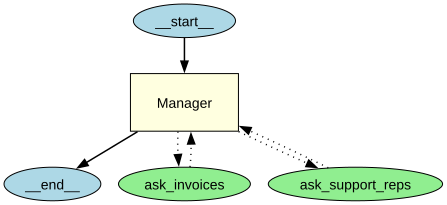

In [16]:
manager = Agent(
    name="Manager",
    instructions=("You help the support reps of a music shop. Ask the specialists for every fact; never answer from "
                  "memory. Answer in one or two sentences."),
    model=MODEL,
    tools=[
        invoices_agent.as_tool(
            tool_name="ask_invoices",
            tool_description="Ask the invoices specialist about a customer's invoices: how many, and their total.",
        ),
        reps_agent.as_tool(
            tool_name="ask_support_reps",
            tool_description="Ask the support-rep specialist who looks after a customer.",
        ),
    ],
    model_settings=SETTINGS,
)

draw_graph(manager)

The drawing looks like the desk agent's: one box, and ellipses with dotted arrows both ways. From the manager's
side a specialist is one more tool. The specialists' own lookups do not appear.

The cell below also prints the manager's part of `new_items`, the list of what a run added to the conversation: its
tool calls and what came back.

Before you run it: which agent will write the final answer?

In [17]:
as_tools = await Runner.run(manager, PUJA)

print(as_tools.final_output)
print("names the rep:", "Jane Peacock" in as_tools.final_output, "| last agent:", as_tools.last_agent.name,
      "| requests:", as_tools.context_wrapper.usage.requests)
print()
for item in as_tools.new_items:
    if item.type == "tool_call_item":
        print("manager asked:", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("answer back:  ", item.output)

Puja Srivastava has 6 invoices totaling $36.64, and her support rep is Jane Peacock.
names the rep: True | last agent: Manager | requests: 8

manager asked: ask_invoices {"input":"How many invoices does Puja Srivastava have, and what is their total amount?"}
manager asked: ask_support_reps {"input":"Who is the support rep for Puja Srivastava?"}
answer back:   Puja Srivastava has 6 invoices, totaling $36.64.
answer back:   Puja Srivastava’s support rep is Jane Peacock.


All three facts, and `last agent` is `Manager`: the manager wrote the answer.

Read the `manager asked` lines. Each specialist got a question the manager wrote for it (`ask_invoices` got *How many
invoices does Puja Srivastava have, and what is their total amount?*), not the rep's original question. Each
specialist answered its part, and both answers came back to the manager, which put them together.

The price is in `requests`: 8 model requests, against 3 for one agent. Each specialist runs its own loop (find the
customer, look up the fact, answer: 3 requests each), and the manager needs one turn to call them and one to write
the reply. That adds up to the 8 printed.

### A handoff: the specialist takes over

Now the same two specialists behind a triage agent. It has no tools, only `handoffs`.

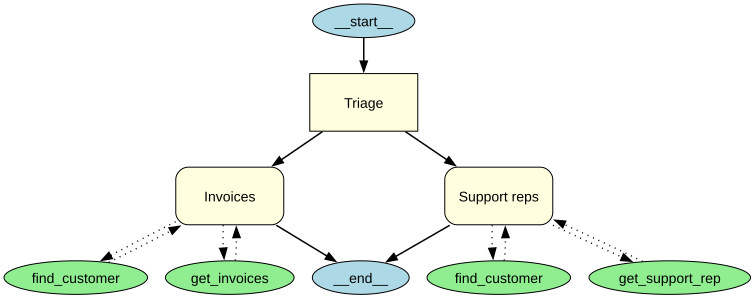

In [18]:
triage = Agent(
    name="Triage",
    instructions=("You route each request to the right specialist. Hand off to Invoices for invoice counts and "
                  "totals, and to Support reps for who looks after a customer."),
    model=MODEL,
    handoffs=[invoices_agent, reps_agent],
    model_settings=SETTINGS,
)

draw_graph(triage)

The drawing changes. The specialists are boxes, each with its own tools, the arrows from `Triage` are solid and
one way, and the arrows to `__end__` leave from the specialists.

Before you run it: the question needs both specialists, and a handoff goes to one. What will the answer hold?

In [19]:
handed = await Runner.run(triage, PUJA)

print(handed.final_output)
print("names the rep:", "Jane Peacock" in handed.final_output, "| last agent:", handed.last_agent.name,
      "| requests:", handed.context_wrapper.usage.requests)
print()
for item in handed.new_items:
    if item.type == "handoff_call_item":
        print("handoff asked:", item.raw_item.name)
    elif item.type == "handoff_output_item":
        print("handoff:      ", item.source_agent.name, "->", item.target_agent.name)
    elif item.type == "tool_call_item":
        print("tool call:    ", item.raw_item.name, item.raw_item.arguments)

Puja Srivastava has 6 invoices totaling **$36.64**. I couldn’t verify who her support representative is with the available lookup tools.
names the rep: False | last agent: Invoices | requests: 4

handoff asked: transfer_to_invoices
handoff asked: transfer_to_support_reps
handoff:       Triage -> Invoices
tool call:     find_customer {"name":"Puja Srivastava"}
tool call:     get_invoices {"customer_id":59}


The reply has the invoices, 6 and \$36.64, and then says it could not verify who her support rep is. `names the rep`
is `False`.

Read the lines below the reply:

- **The triage model asked for both halves.** It wrote two handoffs, `transfer_to_invoices` and
  `transfer_to_support_reps`. (A handoff reaches the model as a tool named `transfer_to_` plus the agent's name.) A
  handoff gives the conversation to one agent, so the SDK took the first and ignored
  the second.
- **`Triage -> Invoices`.** From here the invoices specialist holds the conversation. It called `find_customer` and
  `get_invoices` and wrote the answer, so `last agent` is `Invoices`.
- **`get_support_rep` was never called.** No agent that held control had that tool.

**Key lesson:** nothing stopped this run. There is no error, the reply reads well, and two of its three facts are
right. The rep is missing because control moved to an agent that cannot look it up, and never came back to one
that could. A handoff means the target takes over. It fits a request with one destination, and it loses part of a
request with two.

### Where a handoff fits: a question with one destination

The same triage agent, asked only for the rep:

In [20]:
rep_only = await Runner.run(triage, "Who is Puja Srivastava's support rep?")

print(rep_only.final_output)
print("last agent:", rep_only.last_agent.name)

Puja Srivastava’s support rep is Jane Peacock.
last agent: Support reps


`Triage` handed the question to `Support reps`, which looked up the rep and answered: Jane Peacock. The
question had one destination, so the answer is complete. A handoff suits a front desk that sends each request to the one team that owns it,
where the specialist should carry on the conversation from then on.

### Who decides the next step

| How the agents are connected | Who decides what runs next | Does control come back? | Requests for Puja's question | Fits |
|---|---|---|---|---|
| one agent, three tools | the agent's model | it never leaves | 3 | tools that fit in one prompt: start here |
| specialists as tools | the manager's model | yes, after each specialist | 8 | a question with several parts that needs one combined answer |
| handoff | the triage model, once | no, the specialist takes over | 4, and the rep is missing | one destination per request |

On this model the handoff lost the rep in every run we made of Puja's question (more than ten), and the specialists as tools kept
all three facts in every run. The handoff's result comes from how the agents are connected, not from an unlucky
run.

**Checkpoint C.** One agent: all three facts. Specialists as tools: all three facts, written by `Manager`, for more
requests. Handoff: the reply has the invoices and no rep, and `last agent` is `Invoices`. The rep-only question is
answered by `Support reps`.

---

## In production

- **Traces hold customer data.** Every run here was also recorded as a trace on the OpenAI account that owns the
  key (notebook 1, Part C). A trace holds the questions and the tool results, customer names included. Decide where
  that may go: `set_tracing_disabled(True)` switches the upload off, and
  `RunConfig(trace_include_sensitive_data=False)` keeps inputs and outputs out of it.
- **Writes need approval.** These tools only read. A tool that changes something (a refund) can be created with
  `needs_approval=True`, so the run pauses until a person agrees. Bonus B2 puts that on this desk.
- **Sessions in a database server.** `SQLiteSession` suits one machine. The SDK has other session classes (for
  example on SQLAlchemy or Redis) for an application that runs on several servers.

## What you can do now

- Build an agent over a database from plain lookup functions, and read its run turn by turn with its cost (Part A).
- Set the reasoning effort of every agent from `models.env` with `ModelSettings` (Part A).
- Keep a conversation across runs with `SQLiteSession`, and say what it stores and sends again (Part B).
- Connect specialists as tools and with a handoff, and say who controls the next step and what each costs (Part C).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH` | `draw_graph` needs the Graphviz program, not only the Python package | install Graphviz (`sudo apt install -y graphviz` on Ubuntu, `brew install graphviz` on a Mac); every other cell works without it |
| `RuntimeError: AgentRunner.run_sync() cannot be called when an event loop is already running.` | `Runner.run_sync` starts its own event loop, and Jupyter already runs one | in a notebook, write `await Runner.run(...)` |
| a follow-up question answered as if it were the first | no session was passed to the second `Runner.run` | pass the same `session=` to every run of the conversation |
| `sqlite3.OperationalError: unable to open database file` | `data/chinook.db` is missing from the repository folder | restore the file (clone the repository again, or `git checkout data/chinook.db`) |

## Challenge

1. **Let the specialists hand back.** Give `Invoices` and `Support reps` a handoff back to a triage agent, with one
   more line in each specialist's instructions: if the request also asks for something its tools cannot look up,
   hand off to Triage with what is still missing. Give the triage one more line too: when a specialist hands back,
   hand off to the specialist for what is still missing. Make copies with `agent.clone(instructions=...)`, which copies an agent and changes the fields we name, and set each copy's
   `handoffs` after all three exist, since each refers to the others. Run Puja's question with `max_turns=12` and
   print the reply, `last_agent`, the requests and the handoff path (from the `handoff_output_item`s in
   `new_items`). Expected: a path that goes back and forth, `Triage -> Invoices -> Triage -> Support reps`, and all
   three facts in most runs but not in every one. A run that misses looks like Part C: the invoices and no rep.
2. **Carry a conversation through the manager.** Give the manager a `SQLiteSession` (under `outputs/`), ask Puja's
   question, then *And what about Helena Holý?* Expected: the second answer has 7, \$49.62 and Steve Johnson, and the
   `input` the manager wrote for each specialist names Helena in full, since the specialists never see the session.

The worked solution, run with its outputs, is in `solved/07b_agents_sdk_at_the_desk_solution.ipynb`.

## Going further

- **`async` and `await` from the beginning.** `07_extra_async_await.ipynb` in this folder goes step by step from a normal
  function to two model calls that run at the same time with `asyncio.gather`.
- **Check the effort the API used.** Each entry of `result.raw_responses` holds the API's reply. Run the desk agent
  once with `model_settings=SETTINGS` and once without, and compare the reasoning tokens in the two usages
  (`usage.output_tokens_details.reasoning_tokens`) on a question that needs arithmetic.
- **Specialists in parallel from our own code.** When we know the parts of a question in advance, our code can run
  two specialists at once with `asyncio.gather(Runner.run(...), Runner.run(...))` and join the answers, with no
  manager model deciding anything.

## Resources

- [OpenAI Agents SDK](https://openai.github.io/openai-agents-python/): the documentation's home, with a quickstart
- [Agents](https://openai.github.io/openai-agents-python/agents/) and
  [Running agents](https://openai.github.io/openai-agents-python/running_agents/): `Agent`, `ModelSettings`,
  `Runner.run`
- [Results](https://openai.github.io/openai-agents-python/results/): `final_output`, `new_items`, `raw_responses`,
  `last_agent`
- [Sessions](https://openai.github.io/openai-agents-python/sessions/): `SQLiteSession` and the other session classes
- [Handoffs](https://openai.github.io/openai-agents-python/handoffs/) and
  [Agent orchestration](https://openai.github.io/openai-agents-python/multi_agent/): handoffs, agents as tools and
  orchestration in code
- [Tracing](https://openai.github.io/openai-agents-python/tracing/): what a trace records and how to control it
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): reasoning effort and
  reasoning tokens

Back to [notebook 1](07a_meet_the_agents_sdk.ipynb). Next:
[Lab 08: How to build and run an agent with Google ADK](../08_Google_ADK/README.md).